# Compute a covariance for the DESI DR3 x LSST Y1 layout

The data vector holds 9964 Fourier entries: 15 LSST Y1 cosmic-shear
(EE) spectra, 76 DESI thin-bin clustering autos and 97 measured
clustering cross pairs, 53 bandpowers each. This notebook computes the
Gaussian, super-sample and connected non-Gaussian terms with the shared
covariance kernels, compares the total against the covariance imported
from the source forecast's sacc file, and saves the calculation.
covariance/README.md documents the survey choices, the Gaussian model
(distortion window on, density-only non-Limber recompute off) and the
measured comparison.


In [1]:
import os
from pathlib import Path
import sys

# BLAS stays serial; the compiled CosmoLike loops own the OpenMP workers.
os.environ["OPENBLAS_NUM_THREADS"] = "1"
root = Path(os.environ["ROOTDIR"])
project = root/"projects/lssty1xdesi"
sys.path.insert(0, str(root/"external_modules/code/cosmolike_core"))
sys.path.insert(0, str(root/"external_modules/code/CAMB"))
sys.path.insert(0, str(project/"interface"))
sys.path.insert(0, str(project/"covariance"))

%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from threadpoolctl import threadpool_limits
import cosmolike_lssty1xdesi_interface as ci
import lssty1xdesi_covariance as survey
from cosmolike_notebook_utils import covariance as cov
from cosmolike_notebook_utils import plot_covariances as pcov
from cosmolike_notebook_utils.covariance.likelihood import (
    read_likelihood_covariance,
    select_likelihood_entries,
)
from cosmolike_notebook_utils.covariance.forecast import save_forecast

blas_limit = threadpool_limits(limits=1, user_api="blas")
ci.set_omp_threads(n=8)
matplotlib.rcParams["mathtext.fontset"] = "stix"
matplotlib.rcParams["font.family"] = "STIXGeneral"

## Choose the measurement and numerical settings

The default run computes the project's native real-space measurement once, at
accuracy boost 1. Set `boosts = [1, 2]` to add the numerical comparison below.
`spaces = ["real", "fourier"]` also computes the Fourier-space (bandpower) version
of the same survey; that companion is illustrative and is not compared to the
supplied matrix.

`accuracy_boost` multiplies the internal interpolation refinements and
multipole cutoffs in [covariance/default.yaml](covariance/default.yaml).
The default power tables have 11,993 wavenumber samples; boost 2 uses
23,985 while retaining all original nodes. The loop below reinitializes
these tables for each boost. `integration_accuracy` independently selects the
quadrature: levels 0–4 use 96, 128, 256, 512 or 1,024 precomputed Gauss–Legendre
nodes of the GNU Scientific Library (GSL) per integration panel. Change it with,
for example, `survey.configuration(accuracy_boost=1, integration_accuracy=1)`;
the default level comes from default.yaml. Keep the scientific bins, cosmology and
CAMB inputs fixed when refining.

The defaults remain **candidate accuracy settings**. Positive definiteness
and a small change in diagonal errors do not establish convergence of all
covariance modes or of Fisher parameter errors. A comparison with the supplied
matrix also mixes physical choices with numerical differences.

The `gaussian` mapping selects the Gaussian spectra separately from numerical
accuracy. Intrinsic alignment (IA) is the correlation of source-galaxy shapes with
the local tidal field; it adds to or cancels part of the lensing signal. Use
`gaussian = {"nonlimber": True, "ia": "NLA", "A1": 0.6}` for an illustrative
constant amplitude of the nonlinear alignment (NLA) model, or add `"A2": 0.2` and
`"B_TA": 0.5` with `"ia": "TATT"` for the tidal alignment and tidal torquing
(TATT) model. A list gives one amplitude per source bin. TATT B modes enter the
real-space shear covariance. These choices change only G: SSC and cNG always use
zero-IA Limber spectra, including the mean signal of SSC's survey-mean term
(galaxy densities are measured relative to the survey's own mean count, which the
long mode also shifts).

The next cell prints the physical inputs, then `survey.initialize` runs CAMB once
and installs the cosmology and the redshift distributions in the compiled
interface. It loads neither the likelihood covariance nor its data vector.

In [2]:
boosts = [1]
# the project measures Fourier bandpowers only
spaces = ['fourier']
# thin lens bins need the distortion window; the density-only
# non-Limber recompute refuses it (covariance/README.md)
gaussian = {"rsd": True, "nonlimber": False, "ia": "none"}
settings = survey.configuration(
    accuracy_boost=boosts[0], gaussian=gaussian,
)
dataset = project/"data/lssty1xdesi_desi_dr3.dataset"

# These are physical assumptions, not inferred from normalized n(z) columns.
for key in (
    "area_deg2",
    "lens_density_arcmin2",
    "source_density_arcmin2",
    "sigma_e_component",
    "bias",
    "cosmology",
    "accuracy_parameters",
    "gaussian",
):
    print(key, settings[key])

camb_tables = survey.initialize(interface=ci, settings=settings)
ci.set_omp_threads(n=8)


def progress(stage, elapsed):
    """Report completed stages of this calculation, in seconds."""
    print(f"{elapsed:8.2f} s  {stage}")

area_deg2 14000.0
lens_density_arcmin2 [0.01082936167352, 0.01241393601417, 0.01371445279599, 0.01473105916016, 0.01542241077122, 0.01611729460945, 0.01698617344099, 0.01713644911427, 0.0172754630184, 0.01640159157357, 0.01639115580312, 0.01559575737408, 0.01413793820604, 0.0131357781773, 0.01223259636727, 0.01114138451507, 0.009887532055177, 0.008780326228551, 0.00183988727071, 0.001966174345313, 0.002138926213946, 0.002235862065136, 0.002325325904411, 0.002524943698506, 0.002755748978221, 0.002943642807154, 0.003172613794578, 0.003365495682999, 0.003506528715691, 0.003718264683962, 0.003860436264681, 0.004039236456294, 0.004171518235265, 0.004293150557735, 0.004457837950283, 0.004839515643669, 0.005256036856826, 0.005730351127169, 0.00591960526448, 0.005694023574581, 0.005566507240093, 0.005177183383335, 0.004852166204356, 0.004355864513582, 0.003814986919188, 0.003056884721847, 0.002537187814646, 0.002052474645267, 0.001600286295513, 0.006318913420935, 0.006941078299822, 0.007638680

## See the 1h, 2h, 3h and 4h matter trispectra

The **trispectrum** describes the connected four-point correlation of the
matter density in Fourier space. Its four density factors can live in one,
two, three or four halos. The halo model separates their contributions:

| Term | Where the four density factors live |
| --- | --- |
| 1h | All four in one halo. |
| 2h | Two halos, partitioned as 1+3 or 2+2 factors. Both partitions enter. |
| 3h | Three halos, partitioned as 2+1+1 factors. |
| 4h | Four different halos. |

For power-spectrum covariance the wavevectors form
$\mathbf{k},-\mathbf{k},\mathbf{q},-\mathbf{q}$.
The helper averages over the angle between $\mathbf{k}$ and $\mathbf{q}$
in the transverse plane.
Below, choose one redshift and plot the diagonal $q=k$:
$\overline{T}=T_{1h}+T_{2h}^{(1+3)}+T_{2h}^{(2+2)}+T_{3h}+T_{4h}$.
This is a **matter trispectrum before survey projection**, not a diagonal
of the LSST covariance matrix. SSC and Gaussian covariance are separate.

The example uses the initialized cosmology, mass panels and integration
level above. Its 65 wavenumbers sample the plot; they do not change the
integration rule. Internally CosmoLike measures lengths in $c/H_0$.
Convert the input $k$ from $h/\mathrm{Mpc}$ and the output trispectrum
back to $(\mathrm{Mpc}/h)^9$ for the figure.

`halo_terms` retains every unordered $(k,q)$ pair, including off-diagonal
pairs. `T2h_13` and `T2h_22` remain separate arrays; only the plotted 2h
curve combines them. The signed logarithmic y axis preserves negative
contributions and is linear within $|\overline{T}|<1\,(\mathrm{Mpc}/h)^9$.
Changing `halo_redshift` below explores another epoch without rerunning CAMB.


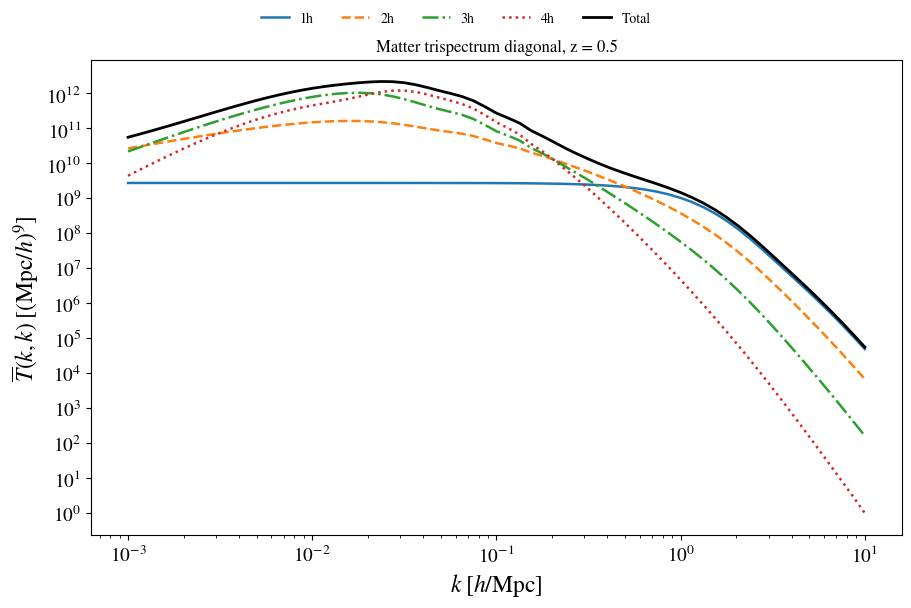

In [3]:
halo_redshift = 0.5
halo_scale_factor = 1.0/(1.0+halo_redshift)
k_hmpc = np.geomspace(start=1.e-3, stop=10.0, num=65)

# c/H0 is 2997.92458 Mpc/h: the factor h is already in the length unit.
# A trispectrum has nine powers of length, whereas power has three.
cover_h0_mpc_over_h = 2997.92458
k_core = k_hmpc*cover_h0_mpc_over_h
halo_terms = cov.halo_trispectrum(
    interface=ci,
    a=halo_scale_factor,
    k=k_core,
    lnm_edges=settings["lnm_edges"],
    accuracy_boost=settings["accuracy_boost"],
    mnu=settings["cosmology"]["mnu"],
    integration_accuracy=settings["integration_accuracy"],
)
terms_mpc_over_h9 = halo_terms["terms"]*cover_h0_mpc_over_h**9

# The five rows distinguish the two possible two-halo partitions.
# Every row uses the same triangular ordering of wavenumber pairs.
T1h = terms_mpc_over_h9[0]
T2h_13 = terms_mpc_over_h9[1]
T2h_22 = terms_mpc_over_h9[2]
T3h = terms_mpc_over_h9[3]
T4h = terms_mpc_over_h9[4]
T2h = T2h_13+T2h_22

# Equal pair indices select q=k, in the order of the original k grid.
diagonal_pairs = halo_terms["first"] == halo_terms["second"]
halo_diagonal = {
    "1h": T1h[diagonal_pairs],
    "2h": T2h[diagonal_pairs],
    "3h": T3h[diagonal_pairs],
    "4h": T4h[diagonal_pairs],
}
pcov.plot_trispectrum_terms(
    k_hmpc=k_hmpc,
    components=halo_diagonal,
    redshift=halo_redshift,
)


## Sample once, read many times

A halo quantity such as the trispectrum above costs a mass integral at every
wavenumber, while a Limber projection asks for it at many changing wavenumbers
$k=(\ell+1/2)/f_K(\chi)$. `cov.DenseLogTable` separates the two costs. It fits a
cubic spline through a few exact samples and evaluates it once on a dense grid
uniform in $\ln k$; every later query reads the two neighboring nodes and
interpolates linearly between them, with no search and no spline evaluation. A
query outside the sampled range raises an error instead of extrapolating. The
power tables above follow the same idea: cubic interpolation fills CAMB's samples
into the 11,993-point tables once, and the C code reads them linearly.

The next cell rebuilds the 1h curve of the figure from every fourth or every second
of its own 65 samples, and prints the largest relative error at the skipped
wavenumbers, which the table never saw. Read the errors in two directions:

- At fixed coarse sampling, the dense grid matters only until every test
  wavenumber falls on a dense node (65 nodes here). From then on the error stays
  the same: more dense nodes cannot restore information missing from the coarse
  samples.
- Halving the coarse stride lowers that floor.

The dense counts follow $2(n-1)+1$, which keeps every old node when the grid
doubles. The 1h term is positive, so the table interpolates its logarithm
(`logarithmic=True`); a signed quantity, such as a response, keeps the default
`logarithmic=False`.

In [4]:
# Rebuild the 1h diagonal of the figure above from a subset of its samples.
# Strides 4 and 2 keep the last index (64), so the table covers every query.
exact_1h = halo_diagonal["1h"]
every_sample = np.arange(len(k_hmpc))
strides = [4, 4, 4, 4, 2, 2]
dense_counts = [17, 33, 65, 129, 65, 129]
# zip pairs the two lists entry by entry: (4, 17), (4, 33), ..., (2, 129).
for stride, ndense in zip(strides, dense_counts):
    coarse = every_sample[::stride]
    skipped = np.setdiff1d(every_sample, coarse)
    table = cov.DenseLogTable(k=k_hmpc[coarse], values=exact_1h[coarse],
                              ndense=ndense, logarithmic=True)
    relative_error = table(k_hmpc[skipped])/exact_1h[skipped]-1.0
    print(f"{len(coarse)} coarse samples, {ndense:3d} dense nodes: "
          f"max |table/exact - 1| = {np.max(np.abs(relative_error)):.1e}")

17 coarse samples,  17 dense nodes: max |table/exact - 1| = 1.3e-01
17 coarse samples,  33 dense nodes: max |table/exact - 1| = 3.5e-02
17 coarse samples,  65 dense nodes: max |table/exact - 1| = 1.0e-02
17 coarse samples, 129 dense nodes: max |table/exact - 1| = 1.0e-02
33 coarse samples,  65 dense nodes: max |table/exact - 1| = 1.8e-03
33 coarse samples, 129 dense nodes: max |table/exact - 1| = 1.8e-03


## Compute G, SSC, cNG and their sum

G describes covariance made from pairs of two-point spectra, including
catalog shot noise ($1/n$) and shape noise ($\sigma_e^2/n$, with $n$ the number
density per steradian). SSC couples measurements through a background density
fluctuation larger than the footprint. cNG is the remaining connected four-point
contribution in the adopted halo model.

The matrix rows follow **observables**: one estimator ($\xi_+$, $\xi_-$,
$\gamma_t$ or $w$) for one tomographic bin pair, with its 26 angular bins
consecutive. The real-space layout has 60 observables (15 + 15 + 25 + 5), so each
matrix is 1,560 × 1,560. The Fourier companion uses one E-mode row per source pair
(675 entries), with integer multipoles weighted by $2\ell+1$, the number of
harmonic modes, inside each band. This project's likelihood is real space;
Cocoa's Fourier-space likelihoods evaluate their mean spectrum at logarithmic band
centers, whereas the generated covariance averages integer modes within bands. It
is therefore an analogous bandpower calculation.

Each computation retains internal cross-bin spectra even when the corresponding
observable is absent from the measured vector: the Gaussian covariance of measured
pairs AB and CD needs the AC, BD, AD and BC spectra. The loop below changes only
numerical resolution, and stores all physical components at each requested boost.
`progress` prints the elapsed time after each stage. At boost 1 the run takes a few
minutes on eight threads, most of it in the shared halo response and trispectrum
stage. `forecast` is the highest-boost result in the native real space; the later
cells use it.

In [5]:
# Each space uses its own projection. Changing the boost refines tables
# while preserving cosmology, observable ordering and measured bins.
results = {}
for space in spaces:
    if space not in ['real', 'fourier']:
        raise ValueError("Choose a measurement space supported by this adapter")
    results[space] = {}
    for boost in boosts:
        refined = dict(settings)
        refined.update(cov.covariance_accuracy(
            accuracy_boost=boost, **settings["accuracy_parameters"],
        ))
        # Reinstall the power tables at this boost, so their k grid
        # is refined along with the covariance integration tables.
        camb_tables = survey.initialize(interface=ci, settings=refined)
        ci.set_omp_threads(n=8)
        print(space, "accuracy boost", boost)
        results[space][boost] = survey.compute(
            interface=ci, settings=refined, space=space, progress=progress,
        )

native_space = 'fourier'
forecast = results[native_space][boosts[-1]]
print("Full covariance shape:", forecast["total"].shape)

fourier accuracy boost 1


    0.58 s  all_pairs_gaussian_spectra
    0.60 s  angular_and_mask_geometry


    1.31 s  gaussian_blocks
    1.32 s  observable_signal


    1.58 s  Matter shell 1/672


    2.64 s  Matter shell 33/672


    3.68 s  Matter shell 65/672


... (17 outputs left out)

   22.74 s  Matter shell 641/672


   23.76 s  shared_halo_response_and_trispectrum


   27.24 s  ssc_and_connected_projection


   27.75 s  total
Full covariance shape: (9964, 9964)


## Apply the project's likelihood cuts

The supplied mask selects measurements, so the same selection must act on both axes
(rows and columns) of G, SSC, cNG and their sum. `select_likelihood_entries`
returns the cut matrices together with `indices`, the original data-vector
positions of the retained entries. Probe labels refer to contiguous groups in the
uncut likelihood vector, including any measured-pair exclusions: `block_sizes`
holds 15 × 26 entries for each shear correlation, 25 × 26 for $\gamma_t$ and
5 × 26 for $w$.

The reader adds the Gaussian and combined non-Gaussian columns of legacy
CosmoCov files (the ten-column text format of the CosmoCov code). It does not
guess how that combined column divides into SSC and cNG.

The next cell draws two figures and prints two lines:

- **Correlation triangles.** Each matrix is normalized by its own diagonal,
  $R_{ij}=C_{ij}/\sqrt{C_{ii}C_{jj}}$. The computed total fills the matrix's lower
  triangle (row > column) and the supplied total its upper triangle; the title
  names them *Lower* and *Upper*. The image puts index 0 at the bottom left, so the
  computed triangle appears above the drawn diagonal and the supplied one below
  it. Differences here are **not** a numerical convergence test. The layout follows
  [Friedrich et al., Fig. 6](https://arxiv.org/abs/2012.08568).
- **Component maps.** Each component is divided by the total's diagonal,
  $C^{\rm comp}_{ij}/\sqrt{C^{\rm tot}_{ii}C^{\rm tot}_{jj}}$, on one shared signed
  color scale; the histogram below the maps collects every entry. G supplies most
  of the variance on the diagonal. SSC and cNG matter mainly through the
  correlations they add between bins, and cNG also raises the variance of
  $\gamma_t$ and $w$ at the smallest angles. The layout adapts
  [Barreira, Krause & Schmidt, Fig. 1](https://arxiv.org/abs/1807.04266).
- **Positivity.** Whether the computed and supplied totals are positive definite,
  and the smallest eigenvalue of each correlation matrix. The next section
  explains these numbers.

Supplied file size: 9964
Retained comparison size: 5309
Mask: lssty1xdesi_desi_dr3.mask


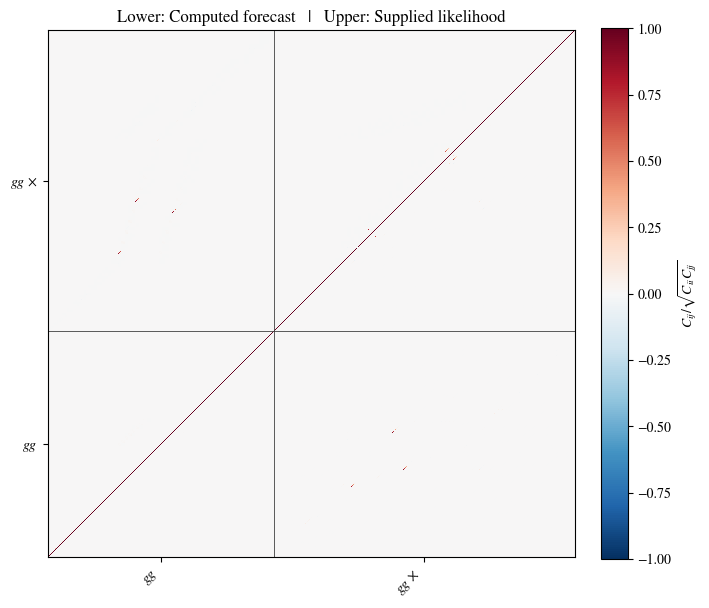

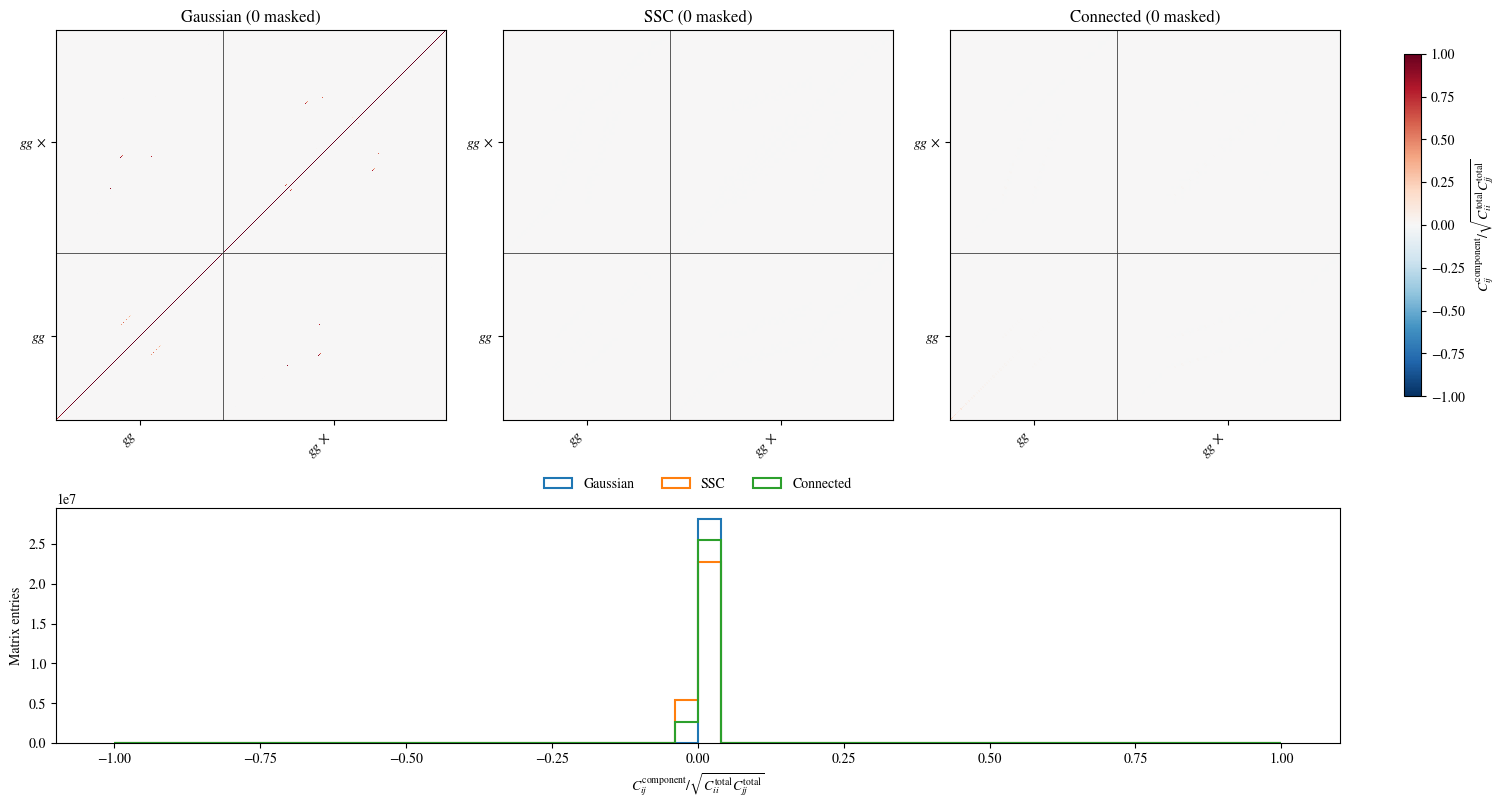

total positive definite: True minimum correlation eigenvalue: 0.012620740587917345


supplied positive definite: True minimum correlation eigenvalue: 0.01894077912637795


In [6]:
supplied = read_likelihood_covariance(dataset=dataset)
block_sizes = [795, 4028, 5141]
block_labels = ['$EE$', '$gg$', '$gg\\,\\times$']
selected = select_likelihood_entries(
    forecast=forecast,
    supplied=supplied,
    block_sizes=block_sizes,
    block_labels=block_labels,
)
print("Supplied file size:", supplied["file_size"])
print("Retained comparison size:", len(selected["indices"]))
print("Mask:", Path(supplied["mask_file"]).name)

pcov.plot_correlation(
    covariance=selected["total"],
    covariance_ref=selected["supplied"],
    block_sizes=selected["block_sizes"],
    block_labels=selected["block_labels"],
    labels=("Computed forecast", "Supplied likelihood"),
)
pcov.plot_covariance_components(
    total=selected["total"],
    components={
        "Gaussian": selected["gaussian"],
        "SSC": selected["ssc"],
        "Connected": selected["cng"],
    },
    block_sizes=selected["block_sizes"],
    block_labels=selected["block_labels"],
    normalization="diagonal",
)

for label in ("total", "supplied"):
    modes = cov.covariance_modes(matrix=selected[label])
    print(label, "positive definite:", modes["positive_definite"],
          "minimum correlation eigenvalue:", modes["correlation_eigenvalues"][0])

## Read the eigenvalues behind the positivity check

A covariance must give every linear combination $v$ of the measurements a
nonnegative variance $v^{\mathsf T}Cv$, and a strictly positive one if $\chi^2$ is
to use its inverse. Equivalently, all its eigenvalues must be positive: the matrix
is **positive definite**. `cov.covariance_modes` checks this on the correlation
matrix $R_{ij}=C_{ij}/\sqrt{C_{ii}C_{jj}}$. Dividing each measurement by its own
standard deviation is an invertible change of units, so it keeps the sign of every
mode, but it removes the many decades that separate the variances of different
probes; in the raw matrix those decades can bury the smallest eigenvalues in
rounding error. The raw eigenvalues are still returned, as `eigenvalues`.

How to read the printed lines:

- The correlation eigenvalues add up to the number of retained entries, so their
  mean is one. A small minimum means some combination of measurements is almost
  fixed by the others; the ratio of the largest to the smallest eigenvalue (the
  condition number) sets how strongly an error in $C$ is amplified in $C^{-1}$, and
  hence in $\chi^2$.
- Only the total that enters the likelihood must be positive definite. SSC is a sum
  of outer products of response vectors, one per radial integration node, and a
  single long-wavelength mode moves all measurements together: one eigenvalue
  carries most of its weight, and most of the others are zero up to rounding, so
  SSC can be reported as not positive definite. A cNG component may even have
  negative variances, here at large angles where they are tiny next to G; the cell
  then reports that no correlation matrix exists for it.
- Nothing is repaired: a negative mode is reported, not clipped.

The figure shows the sorted correlation eigenvalues of G, SSC, the computed total
and the supplied total, after the same cuts. The G, total and supplied spectra
nearly coincide, while the SSC spectrum drops by many decades within its first
hundred modes and then sits at rounding level. A logarithmic axis cannot show
negative values; the printed lines report them.

In [7]:
# Components need not be positive definite; the total that enters chi2 must be.
mode_reports = {}
for name in ("gaussian", "ssc", "cng", "total", "supplied"):
    mode_reports[name] = cov.covariance_modes(matrix=selected[name])
    eigenvalues = mode_reports[name]["correlation_eigenvalues"]
    if eigenvalues is None:
        print(f"{name:9s} has a nonpositive variance: no correlation matrix exists")
        continue
    positive = mode_reports[name]["positive_definite"]
    print(f"{name:9s} positive definite: {positive}; correlation eigenvalues "
          f"from {eigenvalues[0]:.2e} to {eigenvalues[-1]:.2e}")

gaussian  positive definite: True; correlation eigenvalues from 1.26e-02 to 2.90e+00


ssc       positive definite: False; correlation eigenvalues from -1.46e-13 to 1.82e+02


cng       positive definite: False; correlation eigenvalues from -2.33e+02 to 5.98e+02


total     positive definite: True; correlation eigenvalues from 1.26e-02 to 3.70e+00


supplied  positive definite: True; correlation eigenvalues from 1.89e-02 to 3.65e+00


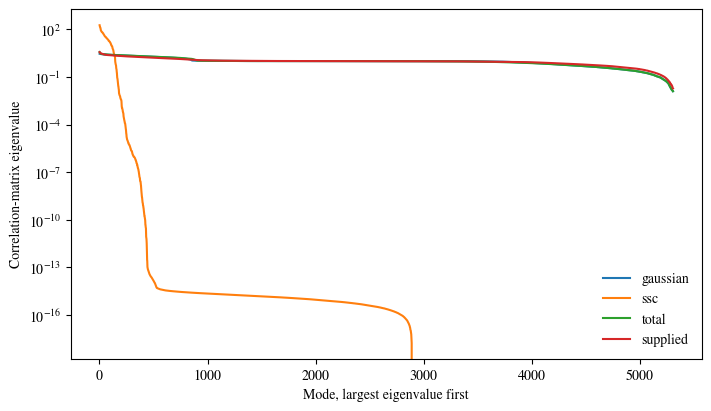

In [8]:
figure, axis = plt.subplots(figsize=(7, 4), constrained_layout=True)
for name in ("gaussian", "ssc", "total", "supplied"):
    # eigvalsh sorts in ascending order; [::-1] puts the largest first.
    descending = mode_reports[name]["correlation_eigenvalues"][::-1]
    mode_number = np.arange(1, len(descending)+1)
    # Matplotlib takes the plotted coordinates positionally, x then y.
    axis.plot(mode_number, descending, label=name)
axis.set_yscale(value="log")
axis.set_xlabel(xlabel="Mode, largest eigenvalue first")
axis.set_ylabel(ylabel="Correlation-matrix eigenvalue")
axis.legend(frameon=False)
plt.show()

## Compare the computed and supplied totals in every direction

The triangle plot compares correlations entry by entry. Both cut matrices come from
`select_likelihood_entries` above, so entry $i$ of each refers to the same measurement,
and the next two cells condense the comparison into numbers.

**Error bars.** The first printed lines give, for each probe, the median and the
range of the ratio of computed to supplied standard deviations $\sqrt{C_{ii}}$
over the retained entries.

**$\chi^2$.** The generalized eigenvalues $\lambda$ of
$C_{\rm computed}\,v=\lambda\,C_{\rm supplied}\,v$, from `cov.compare_covariances`,
bound the change of $\chi^2$ for every possible residual $r$ (data minus model) at
once:

$$\frac{1}{\lambda_{\max}}\;\le\;\frac{r^{\mathsf T}C_{\rm computed}^{-1}\,r}{r^{\mathsf T}C_{\rm supplied}^{-1}\,r}\;\le\;\frac{1}{\lambda_{\min}}.$$

$\lambda_{\max}=2$ would mean that some residual has half the $\chi^2$ under the
forecast; $\lambda_{\min}=0.5$, that another has twice the $\chi^2$. Identical
matrices give $\lambda=1$ for every mode. The histogram shows how the eigenvalues
spread around one.

The two matrices were built with different physical choices (listed at the top of
this notebook) and numerical methods. These numbers therefore measure a difference
in modeling, not a numerical error; the boost comparison below is the numerical
check.

In [9]:
# Computed over supplied standard deviation, probe by probe; zip walks the block
# sizes and labels together, and each probe's retained entries are consecutive.
sigma_ratio = np.sqrt(np.diag(selected["total"])/np.diag(selected["supplied"]))
start = 0
for size, label in zip(selected["block_sizes"], selected["block_labels"]):
    block_ratio = sigma_ratio[start:start+size]
    print(f"{label:12s} sigma computed/supplied: median {np.median(block_ratio):.3f}, "
          f"range {np.min(block_ratio):.3f} to {np.max(block_ratio):.3f}")
    start += size
versus_supplied = cov.compare_covariances(
    matrix=selected["total"], reference=selected["supplied"],
)
generalized = versus_supplied["generalized_eigenvalues"]
print(f"Generalized eigenvalues from {generalized[0]:.3f} to {generalized[-1]:.3f}, "
      f"median {np.median(generalized):.3f}")

$gg$         sigma computed/supplied: median 1.156, range 0.781 to 1.743
$gg\,\times$ sigma computed/supplied: median 1.174, range 0.801 to 1.514


Generalized eigenvalues from 0.534 to 5.870, median 1.248


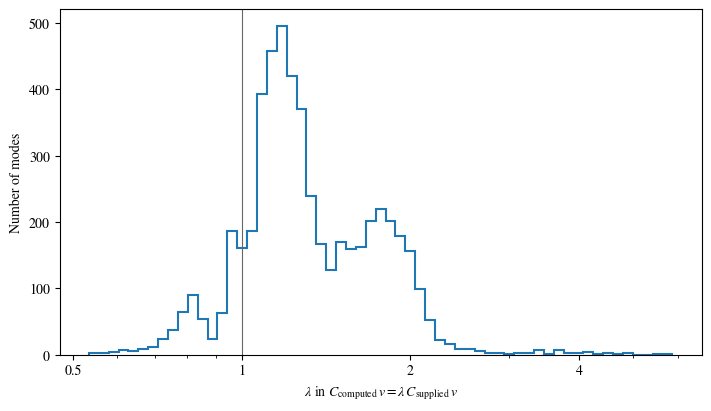

In [10]:
from matplotlib import ticker

figure, axis = plt.subplots(figsize=(7, 4), constrained_layout=True)
# Logarithmic bins treat a factor of two above and below one alike.
edges = np.geomspace(start=generalized[0], stop=generalized[-1], num=60)
axis.hist(x=generalized, bins=edges, histtype="step", linewidth=1.5)
axis.axvline(x=1.0, color="0.4", linewidth=0.8)
axis.set_xscale(value="log")
# Major ticks at powers of two, printed as plain numbers: 0.5, 1, 2, 4, ...
axis.xaxis.set_major_locator(ticker.LogLocator(base=2))
axis.xaxis.set_major_formatter(ticker.FormatStrFormatter("%g"))
axis.set_xlabel(xlabel=r"$\lambda$ in $C_{\rm computed}\,v=\lambda\,C_{\rm supplied}\,v$")
axis.set_ylabel(ylabel="Number of modes")
plt.show()

## See how much SSC and cNG add to the error bars

The component maps show where each term lives in the matrix; this figure measures
what the non-Gaussian terms do to individual error bars. `pcov.plot_covariance_diagonal`,
given the Gaussian part as `covariance_ref`, plots
$100\,(\sigma_i/\sigma_i^{\rm G}-1)$, the percent increase of the standard deviation
$\sigma_i=\sqrt{C_{ii}}$ over its Gaussian-only value, after adding SSC and after
adding cNG as well. The four panels take the first tomographic row of each probe:
$\xi_+$ and $\xi_-$ of source pair (1,1), $\gamma_t$ of lens 1 and source 1, and
$w$ of lens 1. Labels count bins from 1, while the arrays count from 0. The full
matrices are used, before cuts, so every angular bin appears; $\theta$ is the
geometric center of each bin, in arcmin.

What to look for: in the shear panels the non-Gaussian terms add only a few percent,
because shape noise and Gaussian cosmic variance dominate each variance; their main
effect is the correlation between bins seen in the maps and the eigenvalues. For
clustering at small angles, cNG raises the error bar substantially. A dashed curve
that dips just below zero at the largest angles shows the small negative cNG
variances found above: a component may lower a variance, as long as the total keeps
every variance positive.

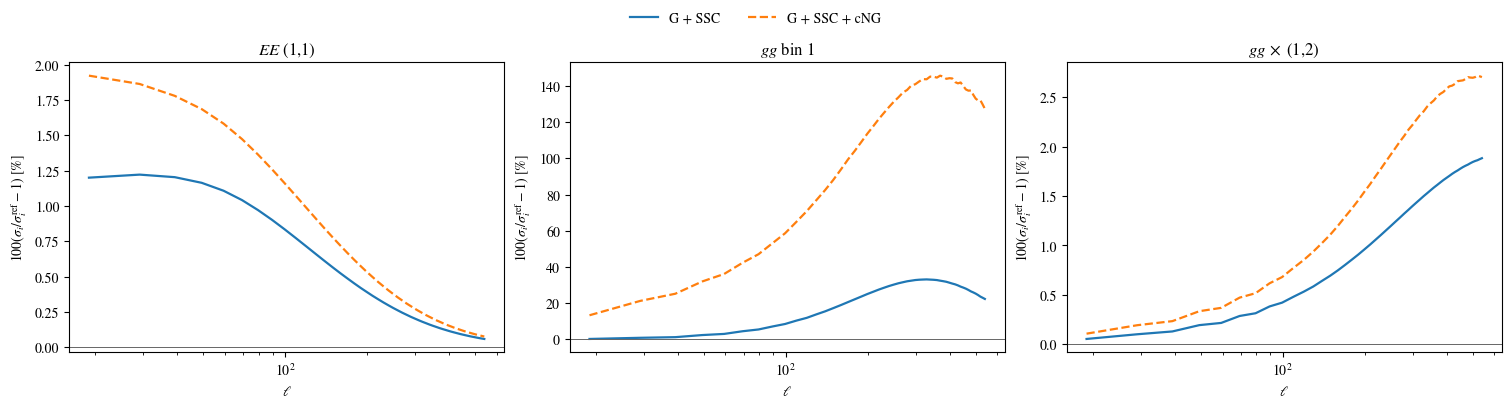

In [11]:
# Each probe block begins with its first tomographic row: EE of
# source pair (1,1), gg of lens bin 1, and the cross of lens bins
# (1,2). The block starts are the running sums of block_sizes:
# 0, 795 and 4823.
block_starts = np.cumsum([0]+block_sizes[:-1])
ntheta = len(forecast["coordinate"])
entries = np.concatenate([np.arange(start, start+ntheta) for start in block_starts])
shown = np.ix_(entries, entries)  # every chosen row with every chosen column
gaussian_only = forecast["gaussian"][shown]
pcov.plot_covariance_diagonal(
    theta_arcmin=forecast["coordinate"],
    covariances={"G + SSC": gaussian_only+forecast["ssc"][shown],
                 "G + SSC + cNG": forecast["total"][shown]},
    panel_labels=[r"$EE$ (1,1)", r"$gg$ bin 1", r"$gg\,\times$ (1,2)"],
    covariance_ref=gaussian_only, coordinate_label=forecast["coordinate_label"],
)

## Check changes with accuracy boost

With two or more boosts, the next cell compares the *computed* matrices after
the same likelihood cuts; with the default `boosts = [1]` it only prints a
reminder. The highest tested boost is the comparison reference. Generalized
eigenvalues solve $C_b v=\lambda\, C_{\rm ref} v$ and bound variance ratios for
every linear combination of retained measurements, as in the comparison with the
supplied matrix above. The reported maximum departure from one is a fraction;
0.01 means 1%.

The error-bar panel selects the first source auto-correlation, $\xi_+$ of source
pair (1,1), which fills the first 26 entries. It shows the percent change of
$\sqrt{C_{ii}}$ relative to the highest boost. This illustrates why convergence
needs more than diagonal agreement. Refine quadrature separately at fixed boost,
and eventually check marginalized Fisher errors and Figure of Merit. No matrix here
has its eigenvalues clipped or its diagonal repaired.

In [12]:
if len(boosts) == 1:
    print("Set boosts = [1, 2] above and rerun to compare numerical accuracy.")
else:
    for boost in boosts:
        current = select_likelihood_entries(
            forecast=results[native_space][boost],
            supplied=supplied,
            block_sizes=block_sizes,
            block_labels=block_labels,
        )
        change = cov.compare_covariances(
            matrix=current["total"], reference=selected["total"],
        )
        print(boost, "maximum fractional variance change:",
              change["maximum_fractional_variance_change"])

    # The first observable is the first source auto-correlation, with
    # all its angular bins or Fourier bands consecutive in the full vector.
    nbin = 53
    reference = forecast["total"][:nbin, :nbin]
    curves = {}
    for boost in boosts[:-1]:
        curves[f"Boost {boost} / {boosts[-1]}"] = (
            results[native_space][boost]["total"][:nbin, :nbin]
        )
    coordinate = forecast["coordinate"]
    pcov.plot_covariance_diagonal(
        theta_arcmin=coordinate,
        covariances=curves,
        panel_labels=['$EE$'],
        covariance_ref=reference,
        coordinate_label='$\\ell$' if native_space == "fourier" else '$\\theta\\;[\\mathrm{arcmin}]$',
    )

Set boosts = [1, 2] above and rerun to compare numerical accuracy.


## Inspect the C++ notebook interface

The compiled wrappers take vectors, matrices and cubes (three-dimensional arrays)
of the Armadillo C++ linear-algebra library, with named physical axes. Python
converts NumPy inputs into owned Armadillo arrays; notebook copies are intentional,
so a later interface call cannot change an array the notebook holds. Whole Gaussian
matrices and individual projection, halo and response components are available for
independent experiments. `help(...)` prints each function's documentation, with
dimensions and units; it works the same way for the Python helpers, for example
`help(cov.covariance_modes)`.

In [13]:
help(ci.covariance_gaussian_fourier)
help(ci.covariance_project)
help(ci.covariance_halo_response)

Help on built-in function covariance_gaussian_fourier in module cosmolike_lssty1xdesi_interface:

covariance_gaussian_fourier(...) method of builtins.PyCapsule instance
    covariance_gaussian_fourier(spectra: object, noise: object, pairs: object, operators: object, ell_min: int, area_sr: float) -> Numpy.ndarray[numpy.float64]
    
    Compute a Gaussian bandpower matrix from supplied field spectra.
    
    spectra[ell,field,field] contains observed signal on consecutive integer
    multipoles starting at ell_min>=0. noise[field] is independent white
    shot/shape power. pairs[observable,2] contains field IDs (A,B).
    operators[band,ell] supplies normalized band weights; the supplied bands
    may overlap. area_sr is the common survey area in steradians.
    Use float64 arrays and int32 pairs. Internal crossed spectra
    are required even when excluded from the measured bandpower vector.
    
    Returns an owned symmetric [nobservable*nband,nobservable*nband] matrix,
    with ban

## Save the calculation

`save_forecast` writes one archive per computed space: `covariance/forecast_real.npz`,
and `forecast_fourier.npz` when that space is requested. Each archive retains every
physical component, the observable ordering, the physical assumptions and the
resolved accuracy settings. `forecast_camb.npz` keeps the CAMB tables of the run,
and `forecast_likelihood_selection.npz` the cut matrices, their original entry
indices and the supplied total used in the plot. Only files in `covariance/` are
written; the supplied files in `data/` remain unchanged. Running this cell again
replaces the computed archives.

In [14]:
for space in spaces:
    save_forecast(
        result=results[space][boosts[-1]],
        filename=project/"covariance"/f"forecast_{space}.npz",
    )
np.savez(file=project/"covariance/forecast_camb.npz", **camb_tables)
np.savez(
    file=project/"covariance/forecast_likelihood_selection.npz",
    **selected,
    dataset=str(dataset.relative_to(project)),
    accuracy_boost=boosts[-1],
)
print("Saved covariance components and likelihood selection.")

Saved covariance components and likelihood selection.


## Reload a saved forecast

An archive lets later work, such as a Fisher forecast, a comparison with another
code or a new figure, start from the matrices without recomputing them.
`np.load(..., allow_pickle=False)` reads only numerical and text arrays, never
executable Python objects, and those are all `save_forecast` writes. The resolved
settings and the stage times are stored as JSON text; `json.loads` turns each back
into a dictionary. The next cell lists the stored arrays, checks that the reloaded
total is bit for bit the matrix computed above, and prints the settings and stage
times that produced it.

In [15]:
import json

archive_path = project/"covariance"/f"forecast_{native_space}.npz"
archive = np.load(file=archive_path, allow_pickle=False)
print("Arrays in", archive_path.name, ":", archive.files)
print("Reloaded total equals the computed one:",
      np.array_equal(archive["total"], forecast["total"]))
saved_settings = json.loads(str(archive["settings_json"]))
for key in ("space", "accuracy_boost", "integration_accuracy", "ell_max", "gaussian"):
    print(f"{key}: {saved_settings[key]}")
# Seconds spent in each stage; "total" covers the whole assembly.
saved_stages = json.loads(str(archive["stages_json"]))
for stage in saved_stages:
    print(f"{saved_stages[stage]:8.2f} s  {stage}")

Arrays in forecast_fourier.npz : ['gaussian', 'ssc', 'cng', 'total', 'signal', 'ssc_normalization_signal', 'rows', 'coordinate', 'coordinate_label', 'geometry', 'coarse_ell', 'pair_area_sr2', 'settings_json', 'stages_json']


Reloaded total equals the computed one: True
space: fourier
accuracy_boost: 1
integration_accuracy: 0
ell_max: 100000
gaussian: {'nonlimber': False, 'rsd': True, 'ia': 'none', 'A1': [0.0, 0.0, 0.0, 0.0, 0.0], 'A2': [0.0, 0.0, 0.0, 0.0, 0.0], 'B_TA': [0.0, 0.0, 0.0, 0.0, 0.0]}
    0.58 s  all_pairs_gaussian_spectra
    0.02 s  angular_and_mask_geometry
    0.71 s  gaussian_blocks
    0.00 s  observable_signal
   22.44 s  shared_halo_response_and_trispectrum
    3.48 s  ssc_and_connected_projection
   27.75 s  total
